# Study 1, notebook 5: the cases side by side

The 2D flux limits of the mock cases, from the results written by `flux_ul.flux_ul`
(`outputs/results/1_flux_ul/<case>.json`). sim_wobble is S240615dg, well localised, observed with
four 20 min wobbles in one field; sim_tiling is S191216ap, 480 deg2 at 90%, observed with a tilepy
tiling of 20 min runs, one field per tile. A missing result is computed here with the default
budget, which takes long for the tiling (every realisation fakes all fields); the cluster entry
point is `scripts/run_flux_ul.py`.

Inputs: the JSON results (or the caches behind them). The real S240615dg follow-up has its own
section at the end, run only when the real DL3 is present.

Imports and figure saver.

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from uuls import flux_ul, paths
from uuls.figures import FigureSaver, COLORS

figs = FigureSaver("1_flux_ul", "5_cases")
CASES = ["sim_wobble", "sim_tiling"]
N_JOBS = 2

Results of the simulated cases: read from disk, or computed if absent. The budget of each is printed.

In [2]:
results = {}
for name in CASES:
    p = flux_ul.result_path(name)
    results[name] = flux_ul.load_result(name) if p.exists() else flux_ul.flux_ul(name, n_jobs=N_JOBS, verbose=False)
    st = results[name]["settings"]
    print(f"{name}: n_bkg {st['n_bkg']}, max_sims {st['max_sims']}, n_closure {st['n_closure']}, seed {st['seed']}")

sim_wobble: n_bkg 1000, max_sims 1500, n_closure 300, seed 0
sim_tiling: n_bkg 500, max_sims 1000, n_closure 200, seed 0


The cases in one table: observation, region of interest, data, and the limit with its 1 sigma Monte
Carlo interval.

In [3]:
def row(r):
    a, e = r["amplitude"], r["energy_flux"]
    return (r["case"], r["skymap"].replace(".fits", ""), r["n_fields"], len(r["obs_ids"]), r["roi_gw_prob"],
            r["lambda_obs"], r["background"]["p_value"], r["target"], a["ul"], a["lo_1sigma"], a["hi_1sigma"],
            e["ul"], r["fit"]["n_sim"], r["closure"]["pull"])


t = Table(rows=[row(results[n]) for n in CASES],
          names=("case", "event", "fields", "runs", "roi_gw_prob", "lambda_obs", "p_value", "target",
                 "phi0_ul", "phi0_lo", "phi0_hi", "eflux_ul", "n_sim", "closure_pull"))
for c in ("roi_gw_prob", "lambda_obs", "p_value", "target", "closure_pull"):
    t[c].format = ".3f"
for c in ("phi0_ul", "phi0_lo", "phi0_hi", "eflux_ul"):
    t[c].format = ".3e"
t.pprint(max_width=200)

   case      event   fields runs roi_gw_prob lambda_obs p_value target  phi0_ul   phi0_lo   phi0_hi   eflux_ul n_sim closure_pull
---------- --------- ------ ---- ----------- ---------- ------- ------ --------- --------- --------- --------- ----- ------------
sim_wobble S240615dg      1    4       0.947     -5.456   0.727 -4.091 2.431e-12 2.282e-12 2.616e-12 1.366e-11   800       -0.175
sim_tiling S191216ap     19   19       0.835     -4.370   0.484 -4.370 8.126e-12 7.576e-12 8.806e-12 4.565e-11  1000       -0.662


The limits as energy flux in 0.6-20 TeV with 1 sigma (bar) and 2 sigma (band) Monte Carlo
intervals, and the GW probability each limit refers to (the ROI).

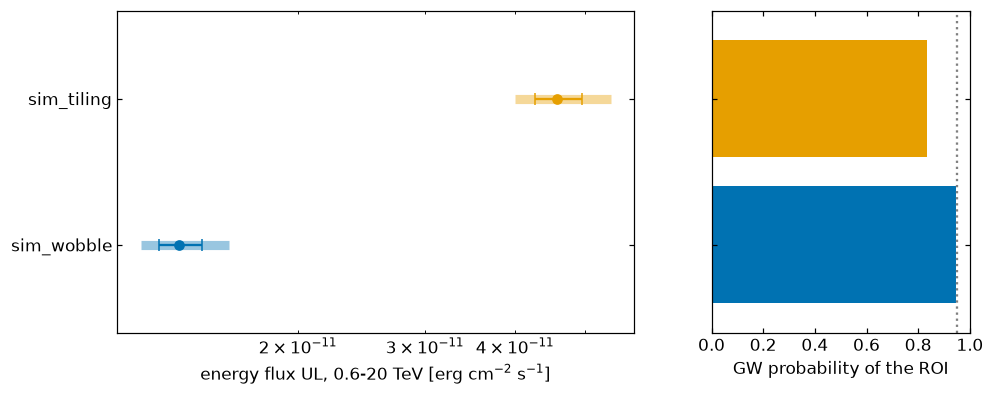

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [2, 1]})
for j, n in enumerate(CASES):
    e = results[n]["energy_flux"]
    axs[0].errorbar([e["ul"]], [j], xerr=[[e["ul"] - e["lo_2sigma"]], [e["hi_2sigma"] - e["ul"]]],
                    fmt="none", color=COLORS[j], alpha=0.4, lw=6)
    axs[0].errorbar([e["ul"]], [j], xerr=[[e["ul"] - e["lo_1sigma"]], [e["hi_1sigma"] - e["ul"]]],
                    fmt="o", color=COLORS[j], capsize=4)
    axs[1].barh(j, results[n]["roi_gw_prob"], color=COLORS[j])
axs[0].set_xscale("log")
axs[0].set_yticks(range(len(CASES)), CASES)
axs[0].set_ylim(-0.6, len(CASES) - 0.4)
axs[0].set_xlabel("energy flux UL, 0.6-20 TeV [erg cm$^{-2}$ s$^{-1}$]")
axs[1].set_yticks(range(len(CASES)), [])
axs[1].set_ylim(-0.6, len(CASES) - 0.4)
axs[1].set_xlim(0, 1)
axs[1].axvline(0.95, color="0.5", ls=":")
axs[1].set_xlabel("GW probability of the ROI")
figs.save(fig, "ul_comparison")
plt.show()

The data against the background distribution of each case, and the cost of each limit in
realisations and wall time (seconds per step, from the run that wrote the result; short when
that run read the realisations from the cache).

In [5]:
for n in CASES:
    r = results[n]
    print(f"{n:11s} p = {r['background']['p_value']:.3f} (S = {r['background']['significance']:+.2f}); "
          f"background median {r['background']['median']:.2f}; fit converged {r['fit']['converged']} "
          f"with +-{r['log10_ul_err_dex']:.3f} dex; closure pull {r['closure']['pull']:+.2f}")
    print(f"{'':11s} time {r['timing_s']}")

sim_wobble  p = 0.727 (S = -0.60); background median -4.09; fit converged True with +-0.030 dex; closure pull -0.18
            time {'prepare_s': 38.6, 'observed_s': 0.0, 'background_s': 0.0, 'fit_s': 0.7, 'closure_s': 0.0}
sim_tiling  p = 0.484 (S = +0.04); background median -4.50; fit converged False with +-0.033 dex; closure pull -0.66
            time {'prepare_s': 3.2, 'observed_s': 0.1, 'background_s': 34.7, 'fit_s': 324.5, 'closure_s': 73.9}


## Real S240615dg

The real LST-1 follow-up of S240615dg, with the reduction's default background (ring) until the
background of real data is settled (plan §10.2). This needs the real DL3 under `data/dl3_real` and the
pointings built from its observation index; it is skipped otherwise.

In [6]:
if paths.REAL_DL3.exists():
    try:
        results["real_S240615dg"] = flux_ul.flux_ul("real_S240615dg", n_jobs=N_JOBS, verbose=False)
        r = results["real_S240615dg"]
        print(f"real_S240615dg: phi0_UL = {r['amplitude']['ul']:.3e} "
              f"[{r['amplitude']['lo_1sigma']:.3e}, {r['amplitude']['hi_1sigma']:.3e}] cm-2 s-1 TeV-1")
    except FileNotFoundError as err:
        print("real case not ready:", err)
else:
    print(f"{paths.REAL_DL3} does not exist: real case skipped")

/data/cta/users-ifae/summer_students/jjimenezq/gw/uncertain-uls/data/dl3_real does not exist: real case skipped


## Outputs

Figure `outputs/figures/1_flux_ul/5_cases/ul_comparison`. Results read from (or written to)
`outputs/results/1_flux_ul/<case>.json`.